# Assignment Module 2: Pet Classification

The goal of this assignment is to implement a neural network that classifies images of 37 breeds of cats and dogs from the [Oxford-IIIT-Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). The assignment is divided into two parts: first, you will be asked to implement from scratch your own neural network for image classification; then, you will fine-tune a pretrained network provided by PyTorch.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


IMPORT

In [22]:
import os
import json
import random
from pathlib import Path
from typing import List, Tuple

import numpy as np
import pandas as pd
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from torch import nn, Tensor
from torch.nn import (
    Module, Conv2d, BatchNorm2d, AdaptiveAvgPool2d,
    Linear, LeakyReLU, MaxPool2d, AvgPool2d, ReLU
)
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchinfo import summary

### Reproducibility

In [2]:
def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(seed=115)

## Dataset

The following cells contain the code to download and access the dataset you will be using in this assignment. Note that, although this dataset features each and every image from [Oxford-IIIT-Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), it uses a different train-val-test split than the original authors.

In [ ]:
# !git clone https://github.com/CVLAB-Unibo/ipcv-assignment-2.git

In [4]:
os.chdir("/content/drive/MyDrive/assignment_2/dataset")
os.getcwd()

'/content/drive/MyDrive/assignment_2/dataset'

In [3]:
class OxfordPetDataset(Dataset):
    def __init__(self, split: str, transform=None) -> None:
        super().__init__()

        self.root = Path("ipcv-assignment-2") / "dataset"
        self.split = split
        self.names, self.labels = self._get_names_and_labels()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx) -> Tuple[Tensor, int]:
        img_path = self.root / "images" / f"{self.names[idx]}.jpg"
        img = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label

    def get_num_classes(self) -> int:
        return max(self.labels) + 1

    def _get_names_and_labels(self) -> Tuple[List[str], List[int]]:
        names = []
        labels = []

        with open(self.root / "annotations" / f"{self.split}.txt") as f:
            for line in f:
                name, label = line.replace("\n", "").split(" ")
                names.append(name),
                labels.append(int(label) - 1)

        return names, labels

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `OxfordPetDataset`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~60%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~60% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

In [4]:
def get_device():
    ''' 
    Utility function to get the device to use for training.
    '''
    if torch.backends.mps.is_available():
        device = "mps"
    elif torch.cuda.is_available():
        device = "cuda"
    else:
        device = "cpu"
    return device

In [5]:
def save_model(model, path: str, epoch: int, best: bool = False, epoch_freq: int = 0) -> None:
    ''' 
    Save checkpoints of the model during training.

    Args:
        model: the model to save.
        path: the directory to save the model.
        epoch: the current epoch number.
        best: whether this is the best model.
        epoch_freq: the frequency for saving the model.
    '''
    os.makedirs(path, exist_ok=True)
    if best:
        # print(f"Saving best model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, "best_model.pt"))
    else:
        # print(f"Saving last model to {path}")
        torch.save(model.state_dict(), os.path.join(path, "last_model.pt"))

    if epoch_freq > 0 and epoch % epoch_freq == 0:
        # print(f"Saving model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, f"epoch_{epoch}.pt"))


### Configuration parameters

In [6]:
NUM_CLASSES = 37
cfg = {
    #Saving parameters
    "save_freq": 0,

    # Pre-processing's parameters.
    "train_size": 112,
    "mean": [0.485, 0.456, 0.406], # Mean values for ImageNet
    "std": [0.229, 0.224, 0.225], # Std values for ImageNet
    "test_size": 128,
    "crop_size": 112,
    "augmentation": True,

    # Training's parameters.
    "batch_size": 32,
    "num_epochs": 130,
    "base_channels": 16,

    # Optimizer's parameters.
    "max_lr": 1.5e-3,
    "schedule_lr": True
}

We compute mean and standard deviation for the given dataset and change the respective parameters in the cfg variable

In [7]:
transform = transforms.Compose([transforms.Resize((cfg["train_size"], cfg["train_size"])),
                                transforms.ToTensor()])
dataset = OxfordPetDataset(split="train", transform=transform)

def compute_mean_std(dataset, batch_size=32):
    """Compute mean and std of a dataset."""
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    mean = 0.
    std = 0.
    total_images_count = 0

    for images, _ in tqdm(loader, desc="Computing mean and std"):

        batch_samples = images.size(0)  # [B, C, H, W]
        images = images.view(batch_samples, images.size(1), -1)  # [B, C, H*W]


        mean += images.mean(2).sum(0)
        std += images.std(2).sum(0)
        total_images_count += batch_samples

    mean /= total_images_count
    std /= total_images_count

    return mean, std

mean, std = compute_mean_std(dataset)

# update the configuration with the computed mean and std with 4 decimal places
cfg["mean"] = [round(m, 4) for m in mean.tolist()]
cfg["std"] = [round(s, 4) for s in std.tolist()]

print(f"Mean: {cfg['mean']}")
print(f"Std: {cfg['std']}")


Computing mean and std: 100%|██████████| 115/115 [00:09<00:00, 11.87it/s]

Mean: [0.4845, 0.4529, 0.3959]
Std: [0.2216, 0.2191, 0.2211]


### Our best model

TripleConvBlock: this block consists of three convolutional layers, each followed, by default, by batch normalization and then an activation function. By default, the block also performs downsampling using a max-pooling layer with stride 2. A skip connection is included by default: when necessary, it automatically adapts both the spatial dimensions and the number of channels to match the main path.

FullModel: this model stacks three TripleConvBlocks with default settings, followed by one TripleConvBlock without downsampling. The network then applies global average pooling before a final fully connected layer. Each TripleConvBlock (except the last) doubles the number of channels, reducing the computational cost. Global average pooling not only improves performance but also reduces the number of activations fed to the fully connected layer. The final FC layer outputs a probability distribution over the target classes.

In [8]:
class TripleConvBlock(Module):
    
    def __init__(self, in_ch: int, out_ch: int, downsample: bool = True, skip: bool = True, batch_norm: bool = True, activation = LeakyReLU) -> None:
        '''
        Triple convolution block.
        Args:
            in_ch: number of input channels.
            out_ch: number of output channels.
            downsample: whether to downsample the input.
            skip: whether to use a skip connection.
            batch_norm: whether to use batch normalization.
            activation: the activation function to use (default is LeakyReLU).
        '''

        super().__init__()

        self.skip = skip
        self.batch_norm = batch_norm

        self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False)
        self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.conv3 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False) 
        if batch_norm:
            self.bn1 = BatchNorm2d(out_ch)
            self.bn2 = BatchNorm2d(out_ch)
            self.bn3 = BatchNorm2d(out_ch)

        self.act  = activation()
        self.pool = MaxPool2d(2) if downsample else nn.Identity()

        if skip:
            self.skip_adapt = nn.Sequential(
                MaxPool2d(2) if downsample else nn.Identity(),
                Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                BatchNorm2d(out_ch)
            )

        self.need_changes = downsample or (in_ch != out_ch)


    def forward(self, x: Tensor) -> Tensor:
        if self.skip:
            identity = x if not self.need_changes else self.skip_adapt(x)

        if self.batch_norm:
            out = self.act(self.bn1(self.conv1(x)))
            out = self.act(self.bn2(self.conv2(out)))
            out = self.bn3(self.conv3(out))
        else:
            out = self.act(self.conv1(x))
            out = self.act(self.conv2(out))
            out = self.conv3(out)

        out = self.pool(out)

        if self.skip:
            out = self.act(out + identity)
        else:
            out = self.act(out)

        return out


class FullModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        ''' 
        Our baseline model.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [23]:
full_model = FullModel(num_classes=NUM_CLASSES, base_channels=cfg["base_channels"])
summary(
    full_model,
    input_size=(1, 3, cfg["train_size"], cfg["train_size"]),
    col_names=("input_size", "output_size", "num_params"),
    verbose=1
)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
FullModel                                [1, 3, 112, 112]          [1, 37]                   --
├─TripleConvBlock: 1-1                   [1, 3, 112, 112]          [1, 16, 56, 56]           --
│    └─Sequential: 2-1                   [1, 3, 112, 112]          [1, 16, 56, 56]           --
│    │    └─MaxPool2d: 3-1               [1, 3, 112, 112]          [1, 3, 56, 56]            --
│    │    └─Conv2d: 3-2                  [1, 3, 56, 56]            [1, 16, 56, 56]           48
│    │    └─BatchNorm2d: 3-3             [1, 16, 56, 56]           [1, 16, 56, 56]           32
│    └─Conv2d: 2-2                       [1, 3, 112, 112]          [1, 16, 112, 112]         432
│    └─BatchNorm2d: 2-3                  [1, 16, 112, 112]         [1, 16, 112, 112]         32
│    └─LeakyReLU: 2-4                    [1, 16, 112, 112]         [1, 16, 112, 112]         --
│    └─Conv2d: 2-5                

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
FullModel                                [1, 3, 112, 112]          [1, 37]                   --
├─TripleConvBlock: 1-1                   [1, 3, 112, 112]          [1, 16, 56, 56]           --
│    └─Sequential: 2-1                   [1, 3, 112, 112]          [1, 16, 56, 56]           --
│    │    └─MaxPool2d: 3-1               [1, 3, 112, 112]          [1, 3, 56, 56]            --
│    │    └─Conv2d: 3-2                  [1, 3, 56, 56]            [1, 16, 56, 56]           48
│    │    └─BatchNorm2d: 3-3             [1, 16, 56, 56]           [1, 16, 56, 56]           32
│    └─Conv2d: 2-2                       [1, 3, 112, 112]          [1, 16, 112, 112]         432
│    └─BatchNorm2d: 2-3                  [1, 16, 112, 112]         [1, 16, 112, 112]         32
│    └─LeakyReLU: 2-4                    [1, 16, 112, 112]         [1, 16, 112, 112]         --
│    └─Conv2d: 2-5                

## Ablation Models

In [10]:
class OneBlockLessModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''
        Our model with one less convolution block with respect to the full model.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [11]:
class DoubleConvBlock(Module):
    def __init__(self, in_ch: int, out_ch: int, downsample: bool = True) -> None:
        ''' 
        Same as TripleConvBlock but with two convolutional layers instead of three.
        Args:
            in_ch: number of input channels.
            out_ch: number of output channels.
            downsample: whether to downsample the input.
        '''
        super().__init__()
 
        self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False)
        self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
 
        self.bn1 = BatchNorm2d(out_ch)
        self.bn2 = BatchNorm2d(out_ch)
 
 
        self.act  = LeakyReLU(negative_slope=0.1, inplace=True)
        self.pool = MaxPool2d(2) if downsample else nn.Identity()
 
        self.skip_adapt = nn.Sequential(
                MaxPool2d(2) if downsample else nn.Identity(),
                Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                BatchNorm2d(out_ch)
            )
 
        self.need_changes = downsample or (in_ch != out_ch)
 
 
    def forward(self, x: Tensor) -> Tensor:
        identity = x if not self.need_changes else self.skip_adapt(x)
 
        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.pool(out)
 
        out = self.act(out + identity)
        return out
 
class DoubleConvBlockModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''  
        Same as FullModel but with DoubleConvBlocks instead of TripleConvBlocks.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = DoubleConvBlock(3, base_channels)
        self.conv_block2 = DoubleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = DoubleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = DoubleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)
 
    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [ ]:
class NoSkipModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''   
        Same as FullModel but without skip connections.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, skip=False)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, skip=False)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, skip=False)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, skip=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [ ]:
class NoBatchNormModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''   
        Same as FullModel but without batch normalization.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, batch_norm=False)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, batch_norm=False)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, batch_norm=False)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, batch_norm=False)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [ ]:
class ReluModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''  
        Same as FullModel but with ReLU activation instead of LeakyReLU.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels, activation=ReLU)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2, activation=ReLU)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4, activation=ReLU)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False, activation=ReLU)
        self.gap = AdaptiveAvgPool2d(1)
        self.fc = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

In [12]:
class NoGlobalAvgPoolModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        '''
        Same as FullModel but without global average pooling.
        Args:
            num_classes: number of classes in the dataset.
            base_channels: number of base channels for the first convolution block.
        '''
        super().__init__()
        self.conv_block1 = TripleConvBlock(3, base_channels)
        self.conv_block2 = TripleConvBlock(base_channels, base_channels * 2)
        self.conv_block3 = TripleConvBlock(base_channels * 2, base_channels * 4)
        self.conv_block4 = TripleConvBlock(base_channels * 4, base_channels * 4, downsample=False)
        self.fc = Linear(base_channels * 4 * 14 * 14 , num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

### Load Data

instantiate the dataset, define the transformations, and return the dataloaders. Two sets of transformations are implemented: one with data augmentation and one without, allowing easy comparison for ablation studies. We use only RandomResizedCrop and RandomHorizontalFlip as augmentation transformations.

In [ ]:
def get_data_loaders(cfg):
    train_size = cfg["train_size"]
    test_size = cfg["test_size"]
    crop_size = cfg["crop_size"]
    mean = cfg["mean"]
    std = cfg["std"]
    augmentations = cfg["augmentation"]
    batch_size = cfg["batch_size"]

    if augmentations:
        train_tfms = transforms.Compose([
                    transforms.RandomResizedCrop(crop_size),
                    transforms.RandomHorizontalFlip(p=0.5),
                    transforms.ToTensor(),
                    transforms.Normalize(mean=mean, std=std),
                ])

        test_tfms = transforms.Compose([
            transforms.Resize(test_size),
            transforms.CenterCrop(crop_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])

    else:
        train_tfms = transforms.Compose([
            transforms.Resize((train_size, train_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])

        test_tfms = transforms.Compose([
            transforms.Resize((test_size, test_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])


    train = OxfordPetDataset(split="train", transform=train_tfms)
    validation = OxfordPetDataset(split="val", transform=test_tfms)
    test = OxfordPetDataset(split="test", transform=test_tfms)

    # Use a number of workers that is 3/4 of the CPU count, but at least 2.
    nw = max(2, os.cpu_count() * 3 // 4)

    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=nw)
    validation_loader = DataLoader(validation, batch_size=batch_size, shuffle=False, num_workers=nw)
    test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=nw)

    return train_loader, validation_loader, test_loader

### RUN ALL EXPERIMENTS

SAVE RESULTS

In [ ]:
def save_results_json(model_name: str, dictionary: dict, path: str = "./results.json") -> None:
    """
    Save results to a JSON file.

    Args:
        model_name: the name of the model, the key in the JSON file.
        dictionary: the dictionary containing the results of the experiment.
        path: the path to the JSON file.
    """

    if os.path.exists(path):
        with open(path, "r") as f:
            try:
                data = json.load(f)
            except json.JSONDecodeError:
                data = {}  # if the file is empty or corrupted
    else:
        data = {}

    data[model_name] = dictionary

    with open(path, "w") as f:
        json.dump(data, f, indent=4)

SINGLE EXPERIMENT

In [ ]:
def run_experiment(model_name, current_model, config, parameter_to_change):
    '''
    Run the training, evaluation and testing of a specific model.

    Args:
        model_name: the name of the model, used for saving results and checkpoints.
        current_model: the model class to use for the experiment.
        config: the configuration dictionary containing the parameters for the experiment.
        parameter_to_change: a tuple containing the name of the parameter to change and its value,
                             or None if no parameter should be changed.
                             Example: ("batch_size", 64) to change the batch size to 64.
    '''

    cfg = config.copy() # avoid modifying the original config
    
    # update some parameters if needed
    if parameter_to_change:
        param_name, param_value = parameter_to_change
        cfg[param_name] = param_value

    train_loader, validation_loader, test_loader = get_data_loaders(cfg)

    ####### Parameters initialization #######
    epochs = cfg["num_epochs"]
    base_channels = cfg["base_channels"]
    max_lr = cfg["max_lr"]
    save_freq = cfg["save_freq"]
    schedule_lr = cfg["schedule_lr"]
    device = get_device()

    ####### Model initialization #######
    model = current_model(NUM_CLASSES, base_channels).to(device)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params}")

    criterion = cross_entropy
    optimizer = AdamW(model.parameters())
    if schedule_lr:
        lr_scheduler = OneCycleLR(optimizer, max_lr=max_lr, steps_per_epoch=len(train_loader), epochs=epochs)

    ###### History Initialization #######
    lr_values = []
    losses = []
    val_losses = []
    val_accuracies = []
    train_accuracies = []
    total = 0
    correct = 0

    ####### Training Loop #######
    for epoch in range(epochs):

        model.train()
        epoch_loss = 0.0

        for imgs, labels in tqdm(train_loader):

            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)

            # compute and propagate gradients
            loss = criterion(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if schedule_lr:
                lr_scheduler.step()


            epoch_loss += loss.item()

            _, predicted = torch.max(preds, dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)


        train_accuracy = correct / total
        train_accuracies.append(train_accuracy)

        epoch_loss /= len(train_loader)
        losses.append(epoch_loss)

        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False, epoch_freq=save_freq)

        ####### Validation Loop #######
        model.eval()
        val_loss = 0.0
        total = 0
        correct = 0
        with torch.no_grad():
            for imgs, labels in validation_loader:
                imgs = imgs.to(device)
                labels = labels.to(device)

                preds = model(imgs)
                loss = criterion(preds, labels)
                val_loss += loss.item()


                _, predicted = torch.max(preds, dim=1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

        val_loss /= len(validation_loader)
        val_losses.append(val_loss)

        val_accuracy = correct / total
        val_accuracies.append(val_accuracy)

        current_lr = optimizer.param_groups[0]["lr"]
        lr_values.append(current_lr)

        print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Acc: {train_accuracy:.6f} | "
        f"Train Loss: {epoch_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val Acc: {val_accuracy:.6f} |"
        f"LR: {current_lr:.6f}"
        )

        # Update the model if the validation loss is the best so far
        if val_loss <= min(val_losses, default=float('inf')):
            save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)

    ####### END TRAINING LOOP #######

    ####### Test the best model #######
    model_best = current_model(NUM_CLASSES, base_channels).to(device)
    model_best.load_state_dict(torch.load(f"./checkpoints/{model_name}/best_model.pt"))

    model_best.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model_best(imgs)
            _, predicted = torch.max(preds, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = correct / total
    print(f"Test Accuracy: {accuracy:.4f}")

    
    ####### Save the results #######

    # Prepare the results dictionary
    dictionary = {
        "cfg": cfg,
        "train_losses": losses,
        "train_accuracies": train_accuracies,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies,
        "lr_values": lr_values,
        "params": total_params,
        "test_accuracy": accuracy
    }
    save_results_json(model_name,dictionary, path="./results.json")

In [ ]:
# Define all models with their parameters to change for ablation study.
all_models = {
    'full_model': {'model': FullModel, 'parameter_to_change': None},
    'one_block_less_model': {'model': OneBlockLessModel, 'parameter_to_change': None},
    'double_conv_model': {'model': DoubleConvBlockModel, 'parameter_to_change': None},
    'no_skip_model': {'model': NoSkipModel, 'parameter_to_change': None},
    'no_batch_norm_model': {'model': NoBatchNormModel, 'parameter_to_change': None},
    'relu_model': {'model': ReluModel, 'parameter_to_change': None},
    'no_global_avg_pool_model': {'model': NoGlobalAvgPoolModel, 'parameter_to_change': None},
    'less_channels_model': {'model': FullModel, 'parameter_to_change': ('base_channels', 8)},
    'no_augmentation_model': {'model': FullModel, 'parameter_to_change': ('augmentation', False)},
    'fixed_lr_model': {'model': FullModel, 'parameter_to_change': ('schedule_lr', False)},
}

RUN ALL

In [ ]:
# Run the experiments for all models defined above.
for model_name, model_info in all_models.items():
    print(f"Running experiment for model: {model_name}")
    run_experiment(
        model_name=model_name,
        current_model=model_info['model'],
        config=cfg,
        parameter_to_change=model_info['parameter_to_change']
    )

### Helper functions to show the results

In [15]:
def read_history(path: str = "./results.json") -> List[float]:
    '''
    Read the training history from the JSON file saved during training.
    Args:
        path: The path to the JSON file.
    '''
    with open(path, "r") as f:
        data = json.load(f)

    return data

In [16]:
def plot_history(history: dict, plot_type: str) -> None:
    ''' 
    Plot the training history for all the models in the ablation study.
    Args:
        history: the history dictionary containing the training history for all models.
        plot_type: the type of plot to create, either "val_losses", "train_losses", etc.
    '''

    baseline_color = "black"
    baseline_marker = "o"
    colors = plt.cm.tab10.colors # Use a colormap for colors
    markers = ['s', 'D', '^', 'v', '>', '<', 'p', '*', 'h'] # Use different markers for each model

    # 3x3 grid of subplots
    fig, axes = plt.subplots(3, 3, figsize=(17, 14))
    axes = axes.flatten()

    # Get the baseline (full_model) losses and epochs 
    baseline_losses = history["full_model"][plot_type]
    epochs = range(1, len(baseline_losses) + 1)

    # Get the names of the other models
    other_models = [m for m in history if m != "full_model"]

    for idx, model_name in enumerate(other_models):
        ax = axes[idx]
        
        # Plot baseline on each subplot
        ax.plot(
            epochs, baseline_losses,
            label="full_model",
            color=baseline_color,
            marker=baseline_marker,
            linewidth=2,
            markersize=4
        )
        
        # Plot other model
        ax.plot(
            epochs, history[model_name][plot_type],
            label=model_name,
            color=colors[idx % len(colors)],
            marker=markers[idx % len(markers)],
            linewidth=1,
            markersize=4
        )
        
        ax.set_title(f"full_model vs {model_name}")
        ax.set_xlabel("Epochs")
        ax.set_ylabel(plot_type)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend()

    plt.tight_layout()
    plt.show()


### Plot and comment results

By examining the following plots and tables, we can see that each component of the full model contributes to achieving the obtained results:
- Removing the skip connections results in performance similar to the baseline. However, we kept them in the full model, as they provide a small improvement without adding significant computational cost.
- Replacing LeakyReLU with ReLU also leads to comparable results, since the network is not very deep. Nonetheless, we observed a slight improvement with LeakyReLU.
- Reducing the number of parameters—either by removing convolutions or decreasing channels (as in the DoubleConvModel, OneBlockLessModel, and LessChannelsModel)—causes a noticeable drop in performance, indicating that all the parameters in the full model contribute meaningfully to its success.
- Removing the global average pooling layer degrades performance, despite the large number of parameters in the network.
- Batch normalization significantly impacts the model’s performance.
- Data augmentation is crucial for generalization: without it, the model’s performance drops considerably, leading to clear overfitting, as evidenced by training accuracy being much higher than validation/test accuracy.


In [17]:
history = read_history(path="./results_new.json")

In [18]:
# Create a DataFrame to summarize the results
df = pd.DataFrame(columns=["model", "num_params", "train_accuracy", "val_accuracy", "test_accuracy"])
for model_name, data in history.items():

    df.loc[len(df)] = [
        model_name,
        data["params"],
        data["train_accuracies"][-1],
        data["val_accuracies"][-1],
        data["test_accuracy"]
    ]

df

,model,num_params,train_accuracy,val_accuracy,test_accuracy
0,full_model,241349,0.775214,0.691930,0.725352
1,no_skip_model,234293,0.759949,0.696838,0.716143
2,one_block_less_model,126149,0.687988,0.615594,0.651138
3,double_conv_model,155749,0.719244,0.635769,0.660888
4,no_batch_norm_model,240293,0.700345,0.591058,0.619177
5,relu_model,241349,0.783573,0.698473,0.709101
6,less_channels_model,61429,0.614210,0.581243,0.609426
7,no_global_avg_pool_model,703109,0.725968,0.622137,0.646804
8,fixed_lr_model,241349,0.714701,0.622683,0.641928
9,no_augmentation_model,241349,0.829002,0.485823,0.516251


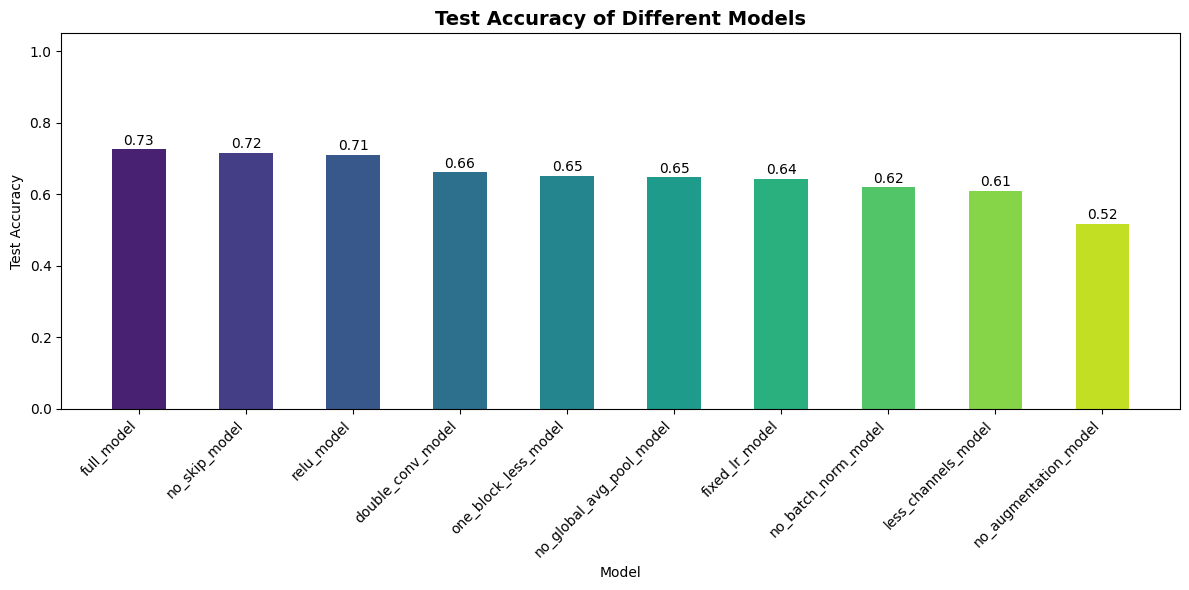

In [19]:
df_sorted = df.sort_values("test_accuracy", ascending=False)

plt.figure(figsize=(12, 6))
bars = plt.bar(df_sorted["model"], df_sorted["test_accuracy"], 
               color=sns.color_palette("viridis", len(df_sorted)), width=0.5)

# Add values on top of the bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, 
             f"{bar.get_height():.2f}", ha='center', va='bottom', fontsize=10)

plt.xlabel("Model"); plt.ylabel("Test Accuracy")
plt.title("Test Accuracy of Different Models", fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right'); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()


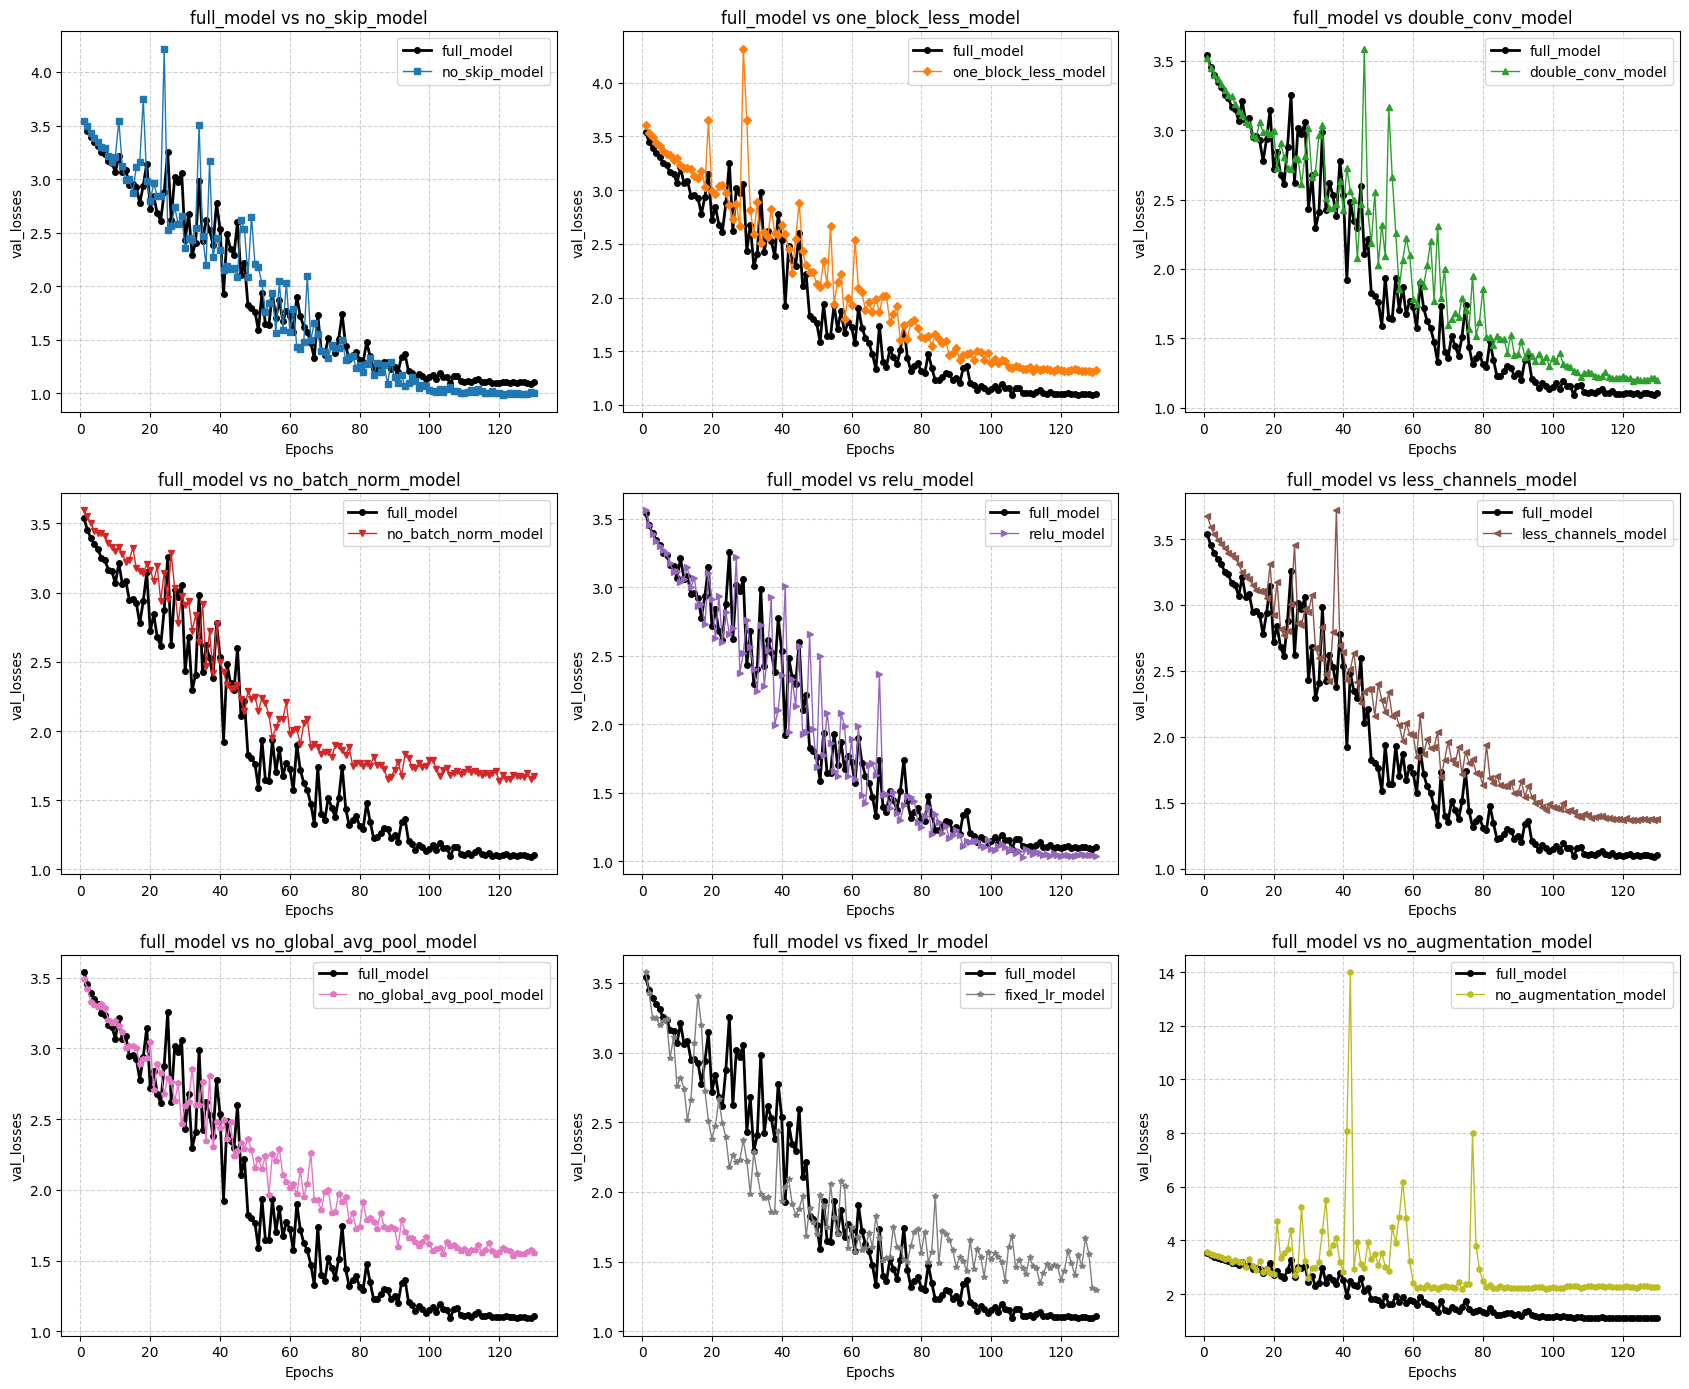

In [20]:
history = read_history(path="./results_new.json")
plot_history(history, "val_losses") # Plot validation losses

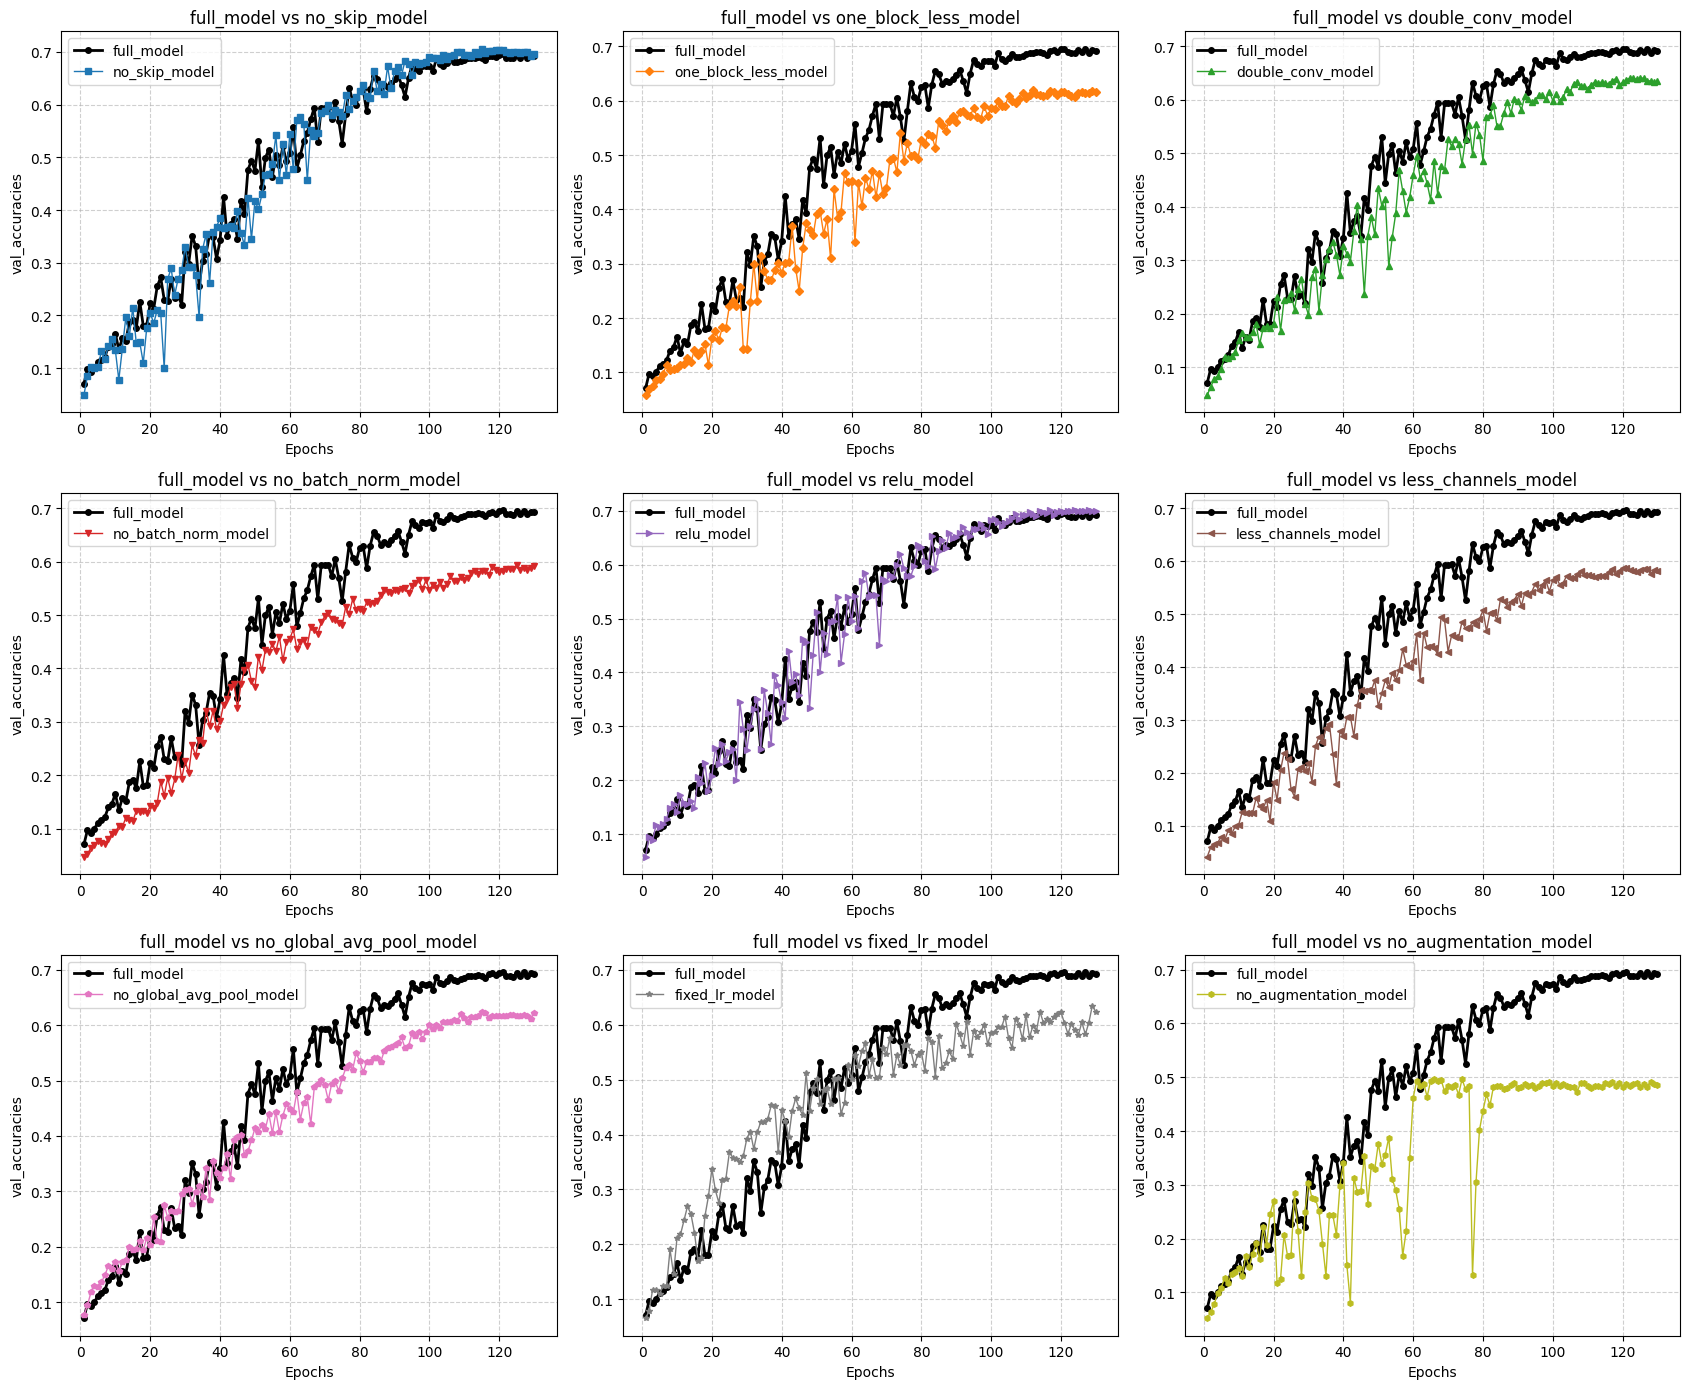

In [21]:
history = read_history(path="./results_new.json")
plot_history(history, "val_accuracies")

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `OxfordPetDataset`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters in order to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~90%.